# House Prices: Exploratory Data Analysis (EDA)

**Notebook 1 of 2** · Kaggle competition *House Prices: Advanced Regression Techniques*

**The problem.** We want to predict the sale price (`SalePrice`, in dollars) of houses in Ames, Iowa, using 79 facts about each house (size, quality, location, age, garage, basement, ...). We have 1460 houses with a known price (`train.csv`) and 1459 houses whose price we must predict (`test.csv`). The Kaggle score is the RMSE (average error) measured on the **log** of the price. Lower is better.

**What this notebook does.** It explores the data, cleans it, builds a few new features and saves two clean tables for `02_Models.ipynb`.

| Step | What we do |
|---|---|
| B1 | First look at the data |
| B2 | Look at the target (`SalePrice`) |
| B3 | Fill the missing values |
| B4 | Make charts to see what changes the price |
| B5 | Remove outliers (train only) |
| B6 | Create new features |
| B7 | Drop useless columns, turn text into numbers, save the files |

**Golden rules used here**
1. We never change the files in `data/raw/`. We only read them and work on copies.
2. Everything we learn from the data (medians, modes) is learned on **train** and then used for both train and test. The test set must never teach us anything.
3. Every change made to train is also made to test, so both tables stay the same.
4. We never delete test rows, because every test house needs a prediction.

## Setup

- `numpy` and `pandas` are for numbers and tables, `matplotlib` and `seaborn` are for charts.
- `RANDOM_STATE = 42` is used whenever something random happens, so the results are the same every time.
- The three folders are written as relative paths (`../`) because this notebook lives in `notebooks/`.

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RANDOM_STATE = 42

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIG = Path("../results/figures")
FIG.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
# B1. First look

**Goal:** see how big the data is and what kind of columns it has, before we change anything.

In [128]:
df_train = pd.read_csv(RAW / "train.csv")
df_test = pd.read_csv(RAW / "test.csv")

print("Train shape:", df_train.shape)
print("Test shape: ", df_test.shape)
print("Columns only in train:", set(df_train.columns) - set(df_test.columns))

Train shape: (1460, 81)
Test shape:  (1459, 80)
Columns only in train: {'SalePrice'}


**What it shows.** Train has 1460 houses and 81 columns, test has 1459 houses and 80 columns. The only column that test does not have is `SalePrice`, because that is exactly what we have to predict.

**Why it matters.** Both tables describe the houses in the same way, so we can clean them in the same way.

In [129]:
df_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**What it shows.** The first 5 houses. Some columns are numbers (areas, years, counts), some are text (zoning, neighborhood, quality grades like `Ex`, `Gd`, `TA`). `NaN` means the value is missing. We will deal with it in B3.

In [130]:
print("Column types in train:")
print(df_train.dtypes.value_counts())

for name, df in [("train", df_train), ("test", df_test)]:
    n_num = df.select_dtypes("number").shape[1]
    n_cat = df.select_dtypes("object").shape[1]
    print(f"{name}: {n_num} numeric columns, {n_cat} categorical (text) columns")

Column types in train:
object     43
int64      35
float64     3
Name: count, dtype: int64
train: 38 numeric columns, 43 categorical (text) columns
test: 37 numeric columns, 43 categorical (text) columns


**What it shows.** Train has 38 numeric columns (this includes `Id` and `SalePrice`) and 43 text columns. Test has 37 numeric columns (no `SalePrice`) and the same 43 text columns.

**Why it matters.** Models can only use numbers. The text columns must be turned into numbers later (B7).

**Careful.** `MSSubClass` is stored as a number, but it is really a building-type code (20, 60, 190, ...). The size of the number means nothing, so we will treat it as text in B7.

In [131]:
df_train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


**What it shows.** For every numeric column: how many values, the mean, the spread (std), the minimum, the quartiles and the maximum.

**Why it matters.** It helps us spot problems. For example, `LotFrontage` has fewer values than the other columns (missing data), and `LotArea` has a maximum far bigger than its 75% value (a few giant lots).

---
# B2. Target: `SalePrice`

**Goal:** understand the number we want to predict.

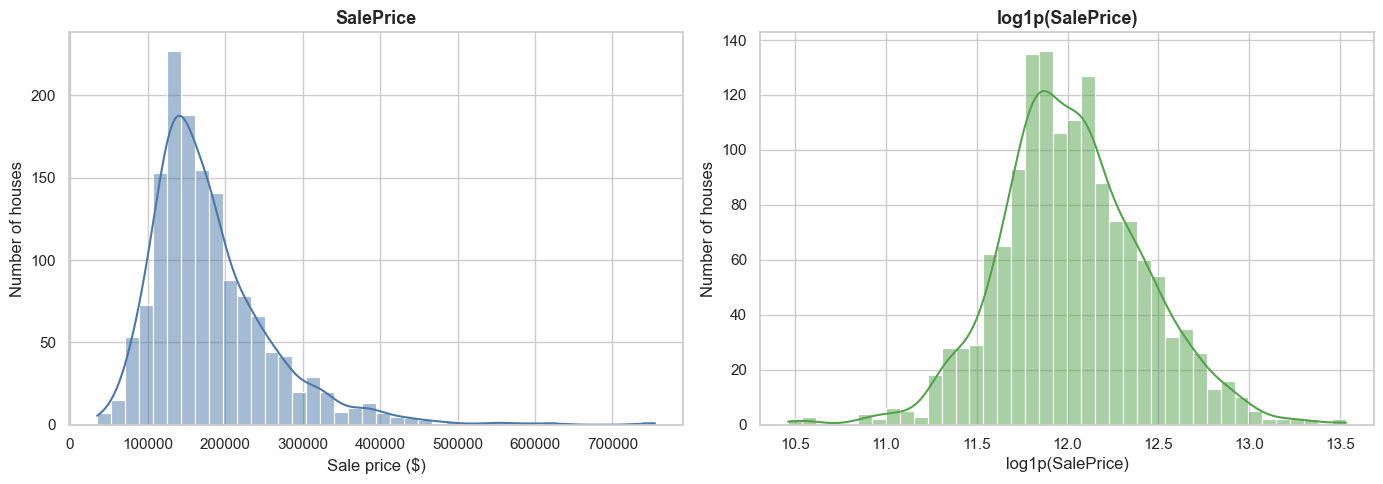

Skew of SalePrice:        1.883
Skew of log1p(SalePrice): 0.121


In [132]:
log_price = np.log1p(df_train["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_train["SalePrice"], bins=40, kde=True, color="#4C78A8", ax=axes[0])
axes[0].set_title("SalePrice", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Number of houses")

sns.histplot(log_price, bins=40, kde=True, color="#54A24B", ax=axes[1])
axes[1].set_title("log1p(SalePrice)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("log1p(SalePrice)")
axes[1].set_ylabel("Number of houses")

plt.tight_layout()
plt.savefig(FIG / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

skew_raw = df_train["SalePrice"].skew()
skew_log = log_price.skew()
print(f"Skew of SalePrice:        {skew_raw:.3f}")
print(f"Skew of log1p(SalePrice): {skew_log:.3f}")

**What it shows.** Left: most houses cost between about \$100k and \$250k, but a few cost much more, so the picture has a long tail to the right. Its skew (a number for how lopsided a distribution is, 0 = symmetric) is **1.88**. Right: after taking the log, the shape is almost symmetric (skew **0.12**).

**Why we use the log.**
1. Models work better when the target is not so lopsided. A few very expensive houses would otherwise pull the model too much.
2. The Kaggle score is measured on the log of the price, so training on the log matches the score.
3. On a log scale, a 10% mistake counts the same for a cheap house and for an expensive house.

`log1p(x)` means `log(1 + x)`. At the end we convert predictions back to dollars with `expm1`.

---
# B3. Missing values

**Goal:** after this step there must be **zero** missing values in train and in test.

**Idea.** In this dataset `NaN` often does **not** mean "unknown". It means "the house does not have this". For example `PoolQC = NaN` means no pool, `GarageType = NaN` means no garage (see `data/raw/data_description.txt`). So we fill the gaps in four different ways:

| Kind of gap | Columns | Fill with |
|---|---|---|
| "None" for text | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, `MasVnrType` | the word `"None"` |
| "None" for numbers | `GarageArea`, `GarageCars`, `GarageYrBlt`, `Bsmt*SF`, `BsmtFullBath`, `BsmtHalfBath`, `MasVnrArea` | `0` |
| Really unknown | `LotFrontage` | median of the same `Neighborhood` |
| Everything else | a few random gaps | the most common value (mode) |

First we make copies, so the raw tables stay untouched.

In [133]:
train = df_train.copy()
test = df_test.copy()

In [134]:
missing = pd.DataFrame({
    "train_count": train.isna().sum(),
    "train_%": (train.isna().sum() / len(train) * 100).round(2),
    "test_count": test.isna().sum(),
    "test_%": (test.isna().sum() / len(test) * 100).round(2),
})

# SalePrice is not in test, so its test numbers are NaN: fill with 0 and keep whole numbers
missing = missing.fillna(0).astype({"train_count": int, "test_count": int})
missing = missing[(missing["train_count"] > 0) | (missing["test_count"] > 0)]
missing = missing.sort_values("train_count", ascending=False)

display(missing)

,train_count,train_%,test_count,test_%
PoolQC,1453,99.52,1456,99.79
MiscFeature,1406,96.30,1408,96.50
Alley,1369,93.77,1352,92.67
Fence,1179,80.75,1169,80.12
MasVnrType,872,59.73,894,61.27
FireplaceQu,690,47.26,730,50.03
LotFrontage,259,17.74,227,15.56
GarageYrBlt,81,5.55,78,5.35
GarageQual,81,5.55,78,5.35
GarageFinish,81,5.55,78,5.35


**What it shows.** 19 columns have missing values in train and 33 in test. The top of the table (`PoolQC`, `MiscFeature`, `Alley`, `Fence`) is almost completely empty, because most houses have no pool, no alley, no fence.

**Why it matters.** Most models stop with an error when they see `NaN`. And we must choose the fill value carefully: filling "no pool" with the most common pool quality would invent pools that do not exist.

**Note.** Some columns (`MSZoning`, `KitchenQual`, `Functional`, ...) have no gaps in train but a few in test. We must fill them with values learned on **train**.

In [135]:
# 1) text columns where NaN means "the house does not have it" -> "None"
none_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType",
]

# 2) number columns where NaN means "the house does not have it" -> 0
zero_cols = [
    "GarageArea", "GarageCars", "GarageYrBlt",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "MasVnrArea",
]

for df in [train, test]:
    df[none_cols] = df[none_cols].fillna("None")
    df[zero_cols] = df[zero_cols].fillna(0)

print("Columns filled with 'None':", len(none_cols))
print("Columns filled with 0:     ", len(zero_cols))

Columns filled with 'None': 15
Columns filled with 0:      10


**What it shows.** The "does not have it" gaps are filled. The loop `for df in [train, test]` does the same to both tables.

**Why it matters.** `"None"` becomes a normal category ("this house has no pool"), and `0` is the true value for a missing area (no garage = 0 sq ft). We keep the information instead of hiding it.

In [136]:
# 3) LotFrontage: median of the same neighborhood, learned on TRAIN only
neighborhood_median = train.groupby("Neighborhood")["LotFrontage"].median()
overall_median = train["LotFrontage"].median()

for df in [train, test]:
    df["LotFrontage"] = (
        df["LotFrontage"]
        .fillna(df["Neighborhood"].map(neighborhood_median))
        .fillna(overall_median)          # safety net, only used if a neighborhood has no value
    )

neighborhood_median.round(1).sort_values().head(5)

Neighborhood
BrDale     21.0
MeadowV    21.0
Blueste    24.0
NPkVill    24.0
Blmngtn    43.0
Name: LotFrontage, dtype: float64

**What it shows.** The median `LotFrontage` (street length of the lot, in feet) differs from neighborhood to neighborhood (the table shows the 5 smallest).

**Why it matters.** `LotFrontage` is the only column that is really unknown (every lot touches a street). Houses in the same neighborhood have similar lots, so the neighborhood median is a better guess than one global number. We use the median instead of the mean because a few huge lots would pull the mean up. The medians are computed on train and applied to both tables.

In [137]:
# 4) all other gaps: the most common value (mode) of TRAIN
other_cols = [c for c in test.columns if train[c].isna().any() or test[c].isna().any()]
print("Columns still to fill:", other_cols)

for col in other_cols:
    mode_value = train[col].mode()[0]
    train[col] = train[col].fillna(mode_value)
    test[col] = test[col].fillna(mode_value)

Columns still to fill: ['MSZoning', 'Utilities', 'Exterior1st', 'Exterior2nd', 'Electrical', 'KitchenQual', 'Functional', 'SaleType']


**What it shows.** The few gaps that are left (1 to 4 houses per column) are filled with the most common train value, for example `RL` for `MSZoning` and `TA` for `KitchenQual`.

**Why it matters.** With so few gaps, the most common value is a safe and simple choice. It is taken from train, so the test set does not influence it.

In [138]:
print("Missing values left in train:", train.isna().sum().sum())
print("Missing values left in test: ", test.isna().sum().sum())

assert train.isna().sum().sum() == 0
assert test.isna().sum().sum() == 0
assert len(train) == 1460 and len(test) == 1459   # no rows were lost

Missing values left in train: 0
Missing values left in test:  0


**What it shows.** Both tables have 0 missing values and we did not lose any row. `assert` stops the notebook with an error if this is ever not true.

---
# B4. Visualizations

**Goal:** use charts to find out **what changes the price**. Every chart has a short comment under it.

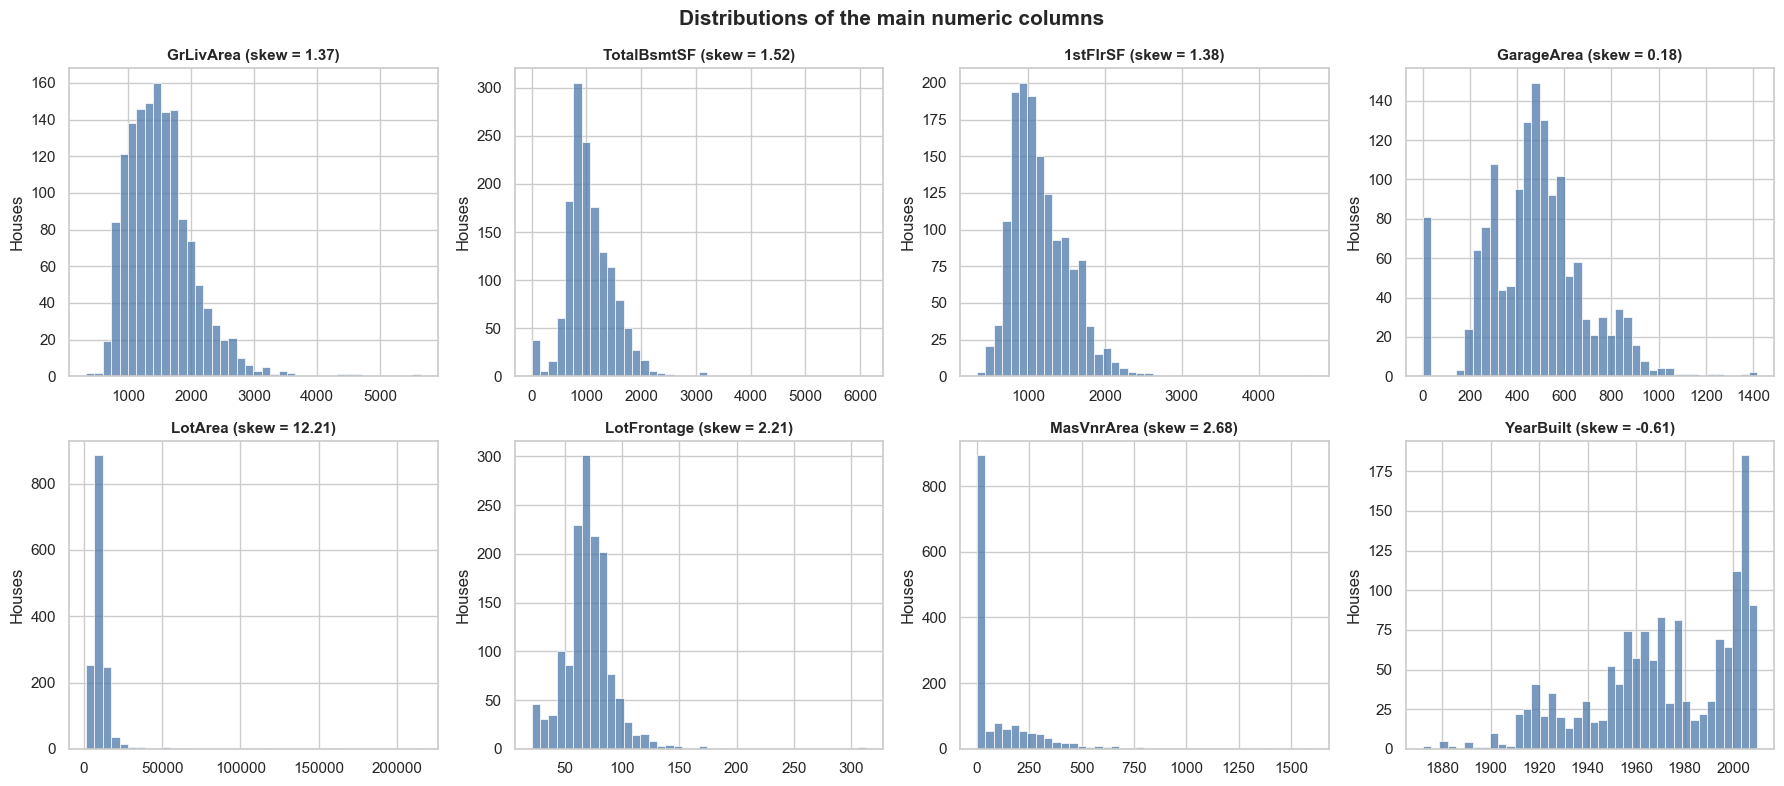

In [139]:
numeric_cols = train.select_dtypes("number").columns.drop(["Id", "SalePrice"])

main_cols = ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea",
             "LotArea", "LotFrontage", "MasVnrArea", "YearBuilt"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), main_cols):
    sns.histplot(train[col], bins=40, color="#4C78A8", ax=ax)
    ax.set_title(f"{col} (skew = {train[col].skew():.2f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Houses")

fig.suptitle("Distributions of the main numeric columns", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows.** How the main numeric columns are spread.
- `GrLivArea`, `TotalBsmtSF` and `1stFlrSF` have a long tail to the right (skew 1.4 to 1.5): most houses are medium-sized, a few are very big. `GarageArea` is almost symmetric (skew 0.18) apart from the tall bar at 0.
- `LotArea` is the most extreme: a few giant lots stretch the whole chart.
- `TotalBsmtSF`, `GarageArea` and `MasVnrArea` have a tall bar at 0: houses with no basement, no garage, no veneer.
- `YearBuilt` has more houses on the right: many houses were built after 1950.

**Why it matters.** Very skewed columns can confuse simple (linear) models, because a few huge values dominate. Tree models do not care.

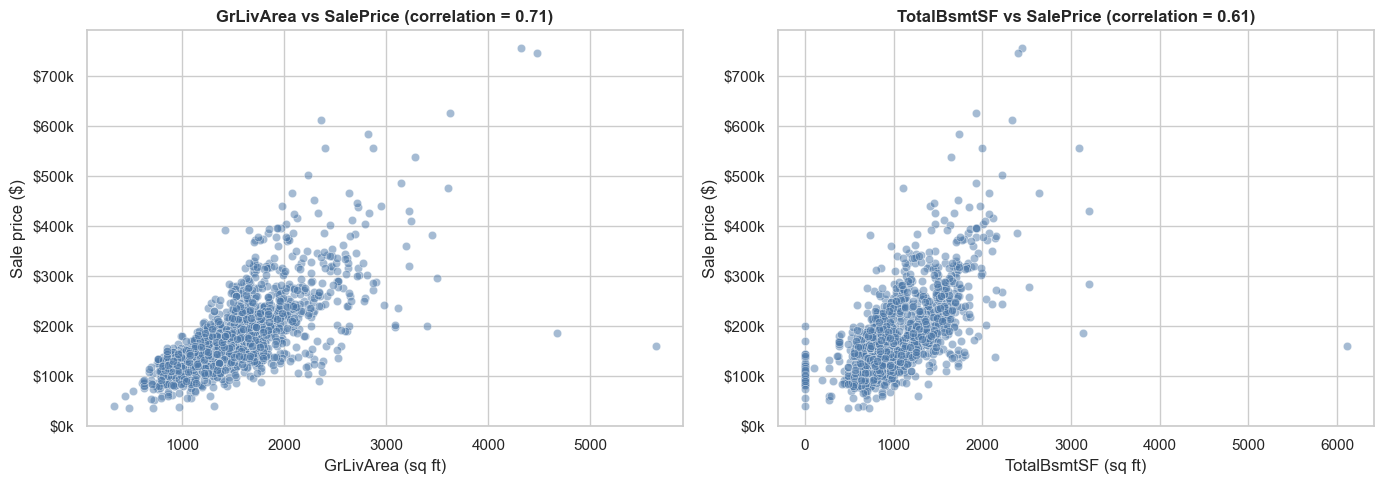

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["GrLivArea", "TotalBsmtSF"]):
    sns.scatterplot(x=train[col], y=train["SalePrice"], alpha=0.5, color="#4C78A8", ax=ax)
    ax.set_title(f"{col} vs SalePrice (correlation = {train[col].corr(train['SalePrice']):.2f})",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{col} (sq ft)")
    ax.set_ylabel("Sale price ($)")
    ax.yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")

plt.tight_layout()
plt.savefig(FIG / "area_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows.** Each dot is one house. Bigger houses are more expensive: the dots go up from left to right.

**Why it matters.** `GrLivArea` (living area above ground) and `TotalBsmtSF` (basement area) are strong, simple predictors. Also look at the **two dots at the bottom right** of the left chart: very big houses with a low price. They do not follow the pattern. They are outliers, and we deal with them in B5. The same house is the extreme dot at the far right of the second chart.

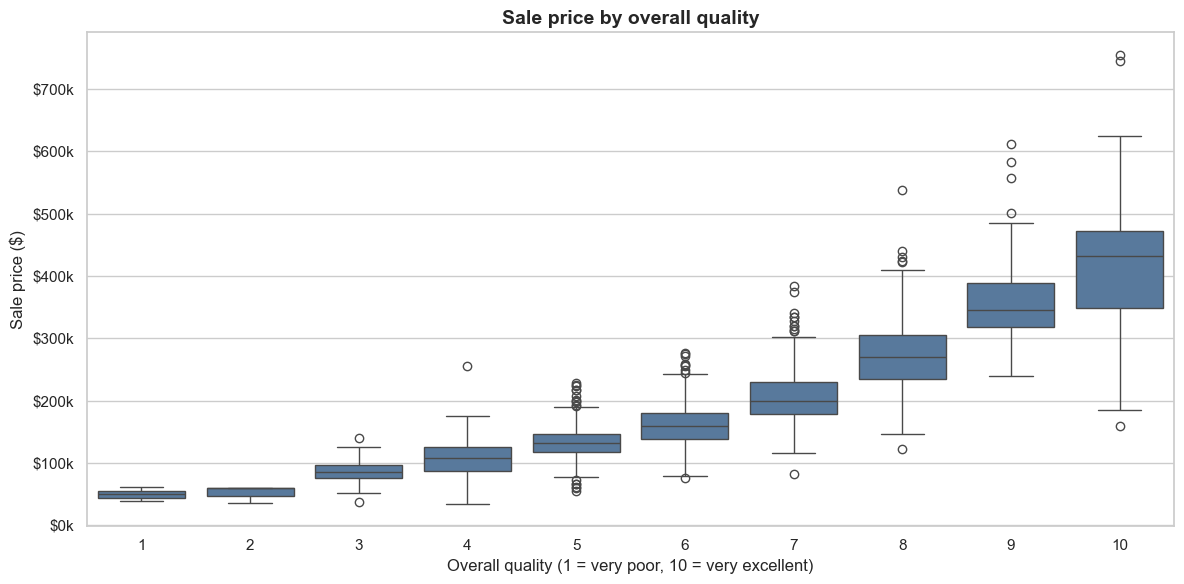

,median price
OverallQual,
1,50150.0
2,60000.0
3,86250.0
4,108000.0
5,133000.0
6,160000.0
7,200141.0
8,269750.0
9,345000.0


In [141]:
qual_median = train.groupby("OverallQual")["SalePrice"].median()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(x=train["OverallQual"], y=train["SalePrice"], color="#4C78A8", ax=ax)
ax.set_title("Sale price by overall quality", fontsize=14, fontweight="bold")
ax.set_xlabel("Overall quality (1 = very poor, 10 = very excellent)")
ax.set_ylabel("Sale price ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")
plt.tight_layout()
plt.savefig(FIG / "overallqual_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

qual_median.to_frame("median price")

**How to read a boxplot.** The line in the box is the median, the box holds the middle 50% of the houses, the whiskers show the normal range and the dots are unusual houses.

**What it shows.** The price goes up with every step of quality: the median is about \$50k at quality 1 and about \$432k at quality 10. The steps get bigger at the top, and expensive houses are also more different from each other.

**Why it matters.** `OverallQual` is the strongest feature in the data (see the heatmap below). The "steps get bigger" shape is another reason to predict the log of the price.

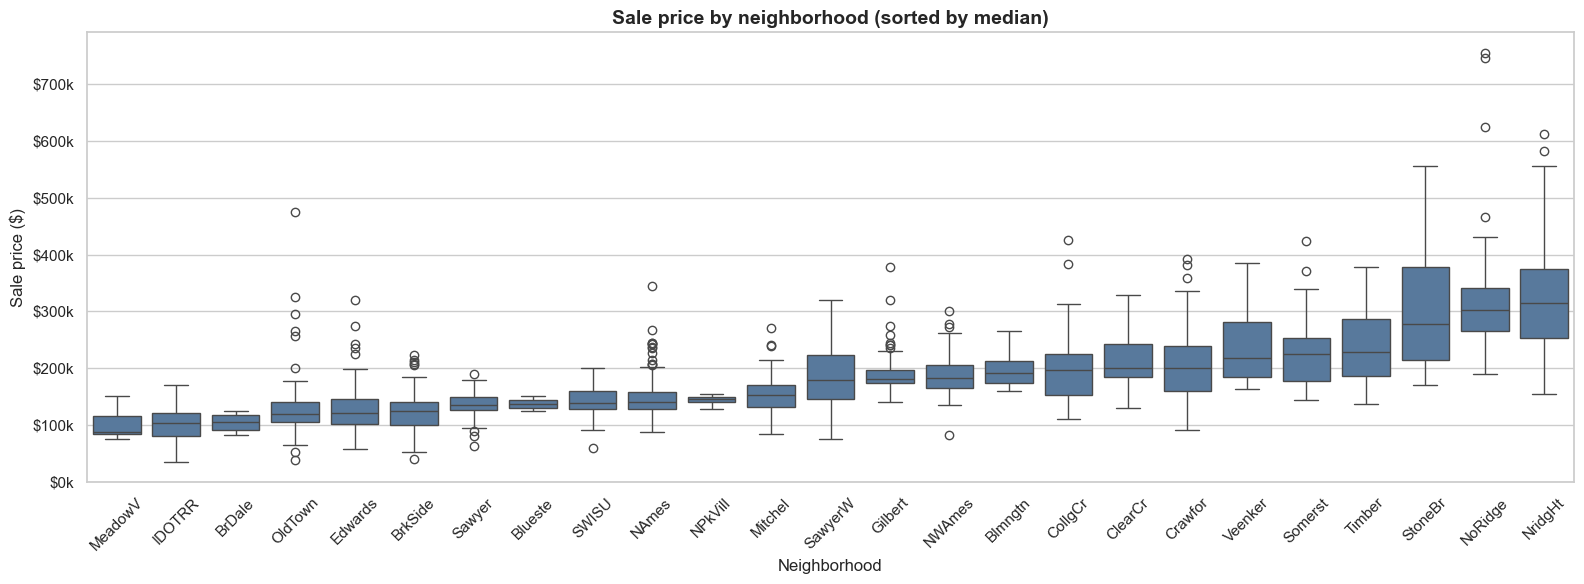

Cheapest: {'MeadowV': 88000.0, 'IDOTRR': 103000.0, 'BrDale': 106000.0}
Most expensive: {'StoneBr': 278000.0, 'NoRidge': 301500.0, 'NridgHt': 315000.0}
Fewest sales: {'Veenker': 11, 'NPkVill': 9, 'Blueste': 2}


In [142]:
neighborhood_median_price = train.groupby("Neighborhood")["SalePrice"].median().sort_values()

fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(x=train["Neighborhood"], y=train["SalePrice"],
            order=neighborhood_median_price.index, color="#4C78A8", ax=ax)
ax.set_title("Sale price by neighborhood (sorted by median)", fontsize=14, fontweight="bold")
ax.set_xlabel("Neighborhood")
ax.set_ylabel("Sale price ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG / "neighborhood_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

print("Cheapest:", neighborhood_median_price.head(3).to_dict())
print("Most expensive:", neighborhood_median_price.tail(3).to_dict())
print("Fewest sales:", train["Neighborhood"].value_counts().tail(3).to_dict())

**What it shows.** Location matters a lot. The cheapest neighborhood (`MeadowV`, median \$88k) is about **3.6 times cheaper** than the most expensive one (`NridgHt`, median \$315k). Expensive neighborhoods also have a wider price range.

**Why it matters.** `Neighborhood` is a strong feature and we keep it. Some neighborhoods have very few sales (see the last print), so their medians are less reliable.

### Categorical columns: distribution and relation to price

So far the only categorical column we looked at was `Neighborhood`. Here are four more. The top row shows **how many houses** are in each category (the distribution), the bottom row shows **the price** for each category.

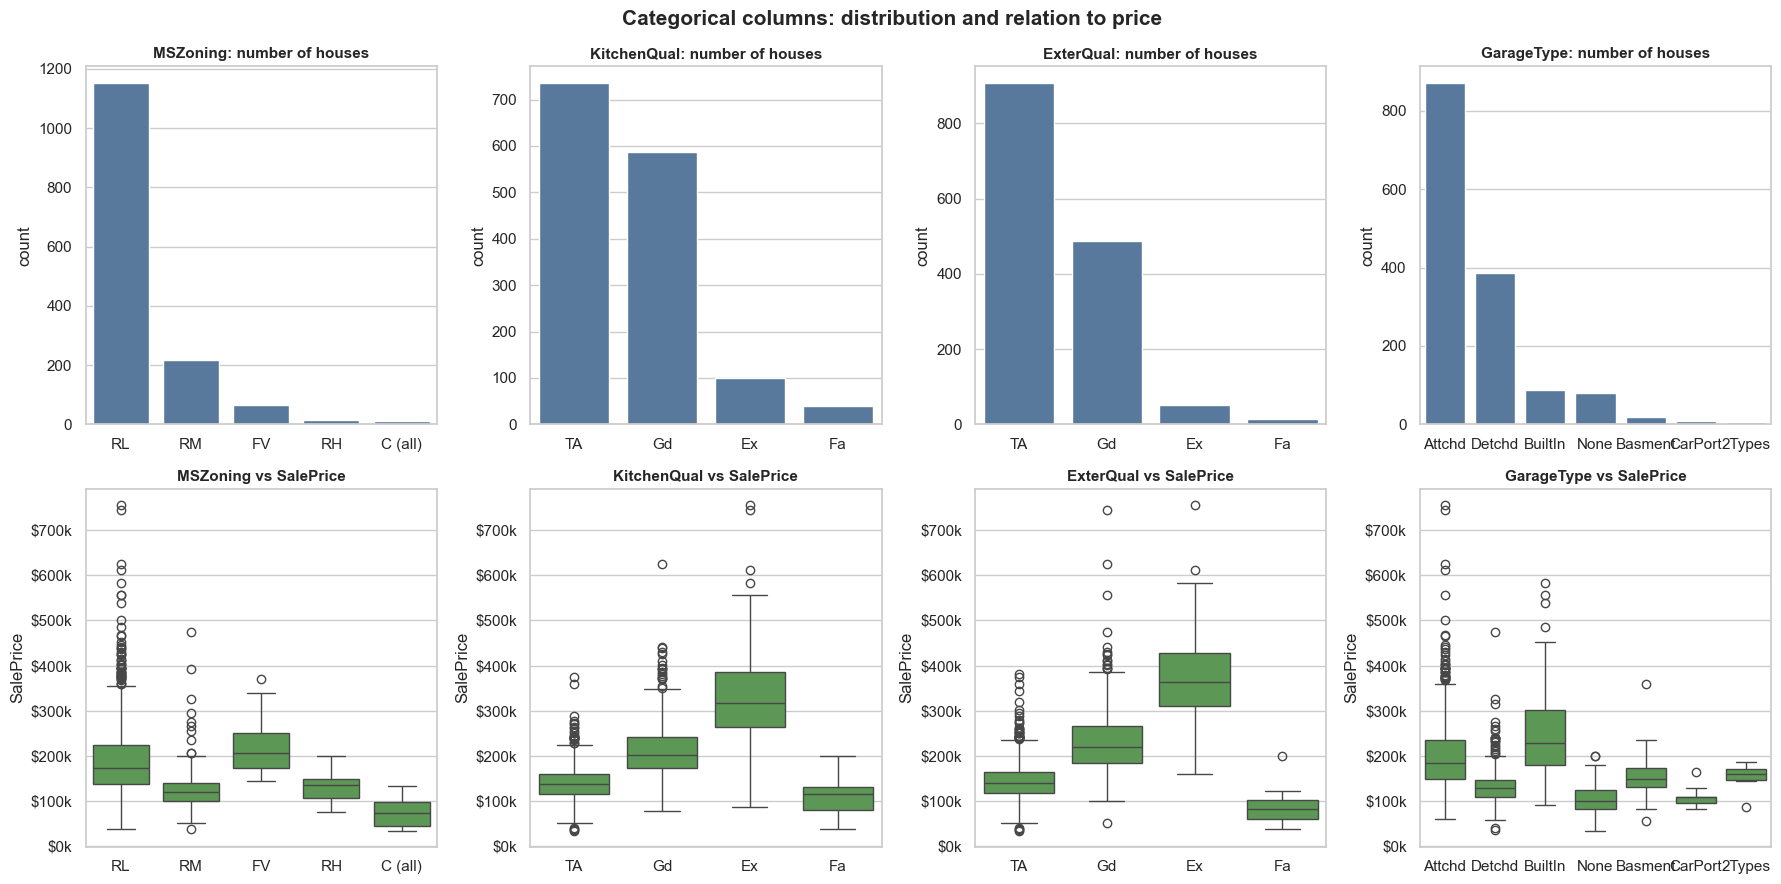

In [143]:
cat_show = ["MSZoning", "KitchenQual", "ExterQual", "GarageType"]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, col in enumerate(cat_show):
    order = train[col].value_counts().index
    sns.countplot(x=train[col], order=order, color="#4C78A8", ax=axes[0, i])
    axes[0, i].set_title(f"{col}: number of houses", fontsize=11, fontweight="bold")
    axes[0, i].set_xlabel("")
    sns.boxplot(x=train[col], y=train["SalePrice"], order=order, color="#54A24B", ax=axes[1, i])
    axes[1, i].set_title(f"{col} vs SalePrice", fontsize=11, fontweight="bold")
    axes[1, i].set_xlabel("")
    axes[1, i].yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")

fig.suptitle("Categorical columns: distribution and relation to price", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "categorical_columns.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows.**
- **How many houses (top row).** Most houses fall into one or two categories. `MSZoning`: 79% are `RL` and 15% are `RM`. `KitchenQual`: half of the houses (50%) have a typical (`TA`) kitchen and 40% a good (`Gd`) one. `ExterQual`: 62% `TA` and 33% `Gd`. `GarageType`: 60% `Attchd` and 27% `Detchd`. Some categories are very small: `MSZoning = C (all)` has only 10 houses, `ExterQual = Fa` 14, `GarageType = CarPort` 9 and `2Types` 6.
- **Price (bottom row).** Price rises clearly with kitchen and exterior quality (`Fa` < `TA` < `Gd` < `Ex`): the median goes from about \$115k to \$137k, \$201k and \$317k for `KitchenQual`, and from \$82k to \$139k, \$220k and \$365k for `ExterQual`. `MSZoning` also matters (`FV` \$206k and `RL` \$174k are the most expensive, `C (all)` \$75k the cheapest). For `GarageType`, built-in and attached garages are the most expensive (\$228k and \$185k), houses with no garage are the cheapest (\$100k).

**Why it matters.** The quality grades (`KitchenQual`, `ExterQual`) are strong features with a natural order. Categories with very few houses give unreliable medians (the boxes are very wide or flat), and the model has only a few examples to learn from. We keep them, because dropping them would lose information, but we should not trust conclusions about them.

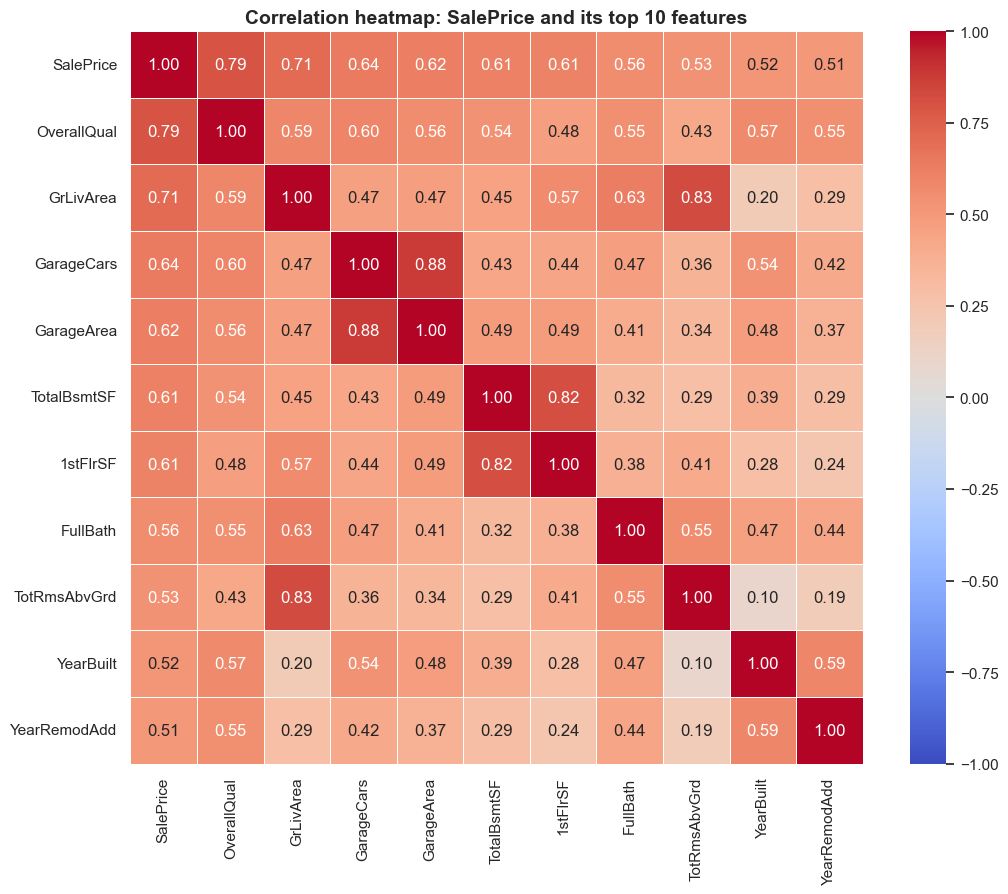

,correlation with SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


In [144]:
corr_price = train[numeric_cols.tolist() + ["SalePrice"]].corr()["SalePrice"]
top10 = corr_price.abs().sort_values(ascending=False).head(11).index    # SalePrice itself + 10 features
top_features = [c for c in top10 if c != "SalePrice"]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train[top10].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation heatmap: SalePrice and its top 10 features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "correlation_heatmap_top10.png", dpi=150, bbox_inches="tight")
plt.show()

corr_price[top_features].round(3).to_frame("correlation with SalePrice")

**How to read it.** Correlation goes from -1 to +1. Near +1 means "when one goes up, the other goes up too". Near 0 means no straight-line relationship.

**What it shows.** The 10 numeric columns most related to the price, from strongest: `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`, `FullBath`, `TotRmsAbvGrd`, `YearBuilt`, `YearRemodAdd`. `OverallQual` (correlation 0.79) is the strongest. Size (living area, garage, basement) and age (`YearBuilt`, `YearRemodAdd`) come next.

**Careful: some of these columns repeat each other.** For example `GarageCars` and `GarageArea` are strongly linked to each other (a bigger garage fits more cars): their correlation is 0.89. `TotalBsmtSF` and `1stFlrSF` are also close (0.80). Two columns with the same information do not help a simple linear model twice, and they make it unstable. This is one reason to use regularized models (Ridge, Lasso) in `02_Models.ipynb`.

---
# B5. Outliers

**Goal:** find houses that do not follow the pattern, and remove them from **train only**.

An outlier is a house that is very different from the rest. A model that tries to fit such a house gets pulled in the wrong direction for all the other houses.

,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
691,692,4316,755000,Normal
1182,1183,4476,745000,Abnorml
1298,1299,5642,160000,Partial


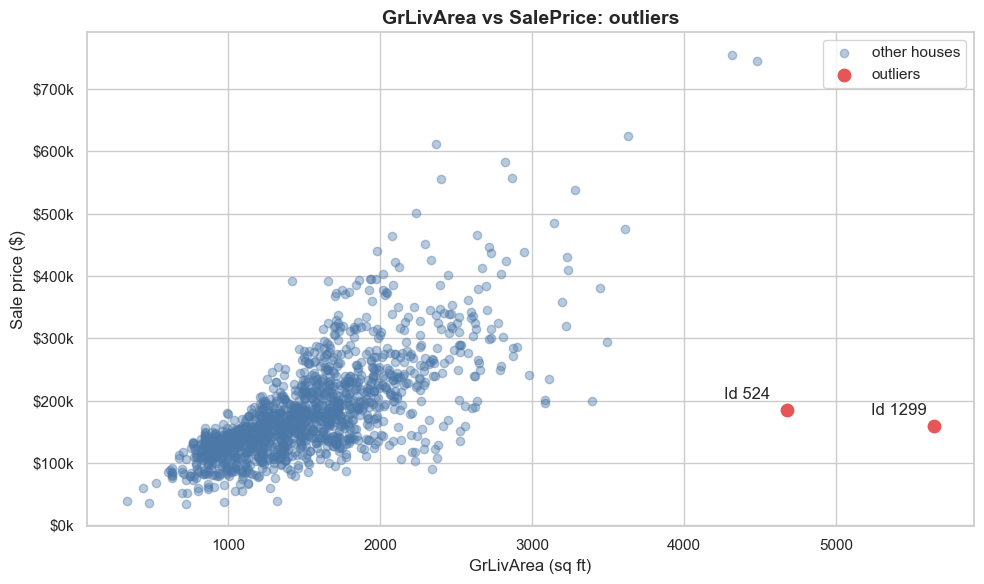

In [145]:
big_houses = train[train["GrLivArea"] > 4000][["Id", "GrLivArea", "SalePrice", "SaleCondition"]]
display(big_houses)

outliers = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(train["GrLivArea"], train["SalePrice"], alpha=0.4, color="#4C78A8", label="other houses")
ax.scatter(outliers["GrLivArea"], outliers["SalePrice"], color="#E45756", s=80, label="outliers")
for _, row in outliers.iterrows():
    ax.annotate(f"Id {row['Id']}", (row["GrLivArea"], row["SalePrice"]),
                textcoords="offset points", xytext=(-45, 8))
ax.set_title("GrLivArea vs SalePrice: outliers", fontsize=14, fontweight="bold")
ax.set_xlabel("GrLivArea (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "outliers.png", dpi=150, bbox_inches="tight")
plt.show()

corr_before = train["GrLivArea"].corr(train["SalePrice"])

**What it shows.** Four houses are bigger than 4000 sq ft. Two of them (Ids 524, 1299) are the biggest in the data but sold for only about \$160k to \$185k, the price of an average house. The other two are big **and** expensive (about \$750k), so they follow the normal pattern.

**Decision.** We remove the two cheap giants from **train**, and keep the two expensive ones.

**Why.**
- Both were `Partial` sales (sold before the building was finished), so the price is not the price of a finished house of that size. They are not typical sales.
- They are only 2 of 1460 houses, so we lose almost nothing, but they pull the model's line down.
- Houses 692 and 1183 are just very big and very expensive, which is normal, so they stay.
- We **never** remove rows from test: every test house needs a prediction.

In [146]:
train = train.drop(outliers.index)

corr_after = train["GrLivArea"].corr(train["SalePrice"])
print("Rows removed from train:", len(outliers))
print("Train rows now:", len(train), "| Test rows:", len(test))
print(f"Correlation GrLivArea vs SalePrice: {corr_before:.3f} -> {corr_after:.3f}")

assert len(train) == 1458 and len(test) == 1459

Rows removed from train: 2
Train rows now: 1458 | Test rows: 1459
Correlation GrLivArea vs SalePrice: 0.709 -> 0.735


**What it shows.** Train now has 1458 houses and test still has 1459. The correlation between `GrLivArea` and the price went up from 0.709 to 0.735.

**Why it matters.** After removing only 2 houses, the link between size and price is clearer. That is the proof that they were hurting. We did not remove more, because other expensive houses are real and the model must learn them.

---
# B6. New features

**Goal:** create new columns that describe a house in a simpler or stronger way, and show that they help.

| New column | How we make it | Why |
|---|---|---|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` | the whole floor area in one number |
| `HouseAge` | `YrSold - YearBuilt` | how old the house was when it was sold |
| `RemodAge` | `YrSold - YearRemodAdd` | years since the last renovation |
| `TotalBath` | full baths + 0.5 x half baths (above ground and basement) | 4 weak columns become 1 |
| `TotalPorchSF` | all porch and deck areas added | many mostly-zero columns become 1 |
| `HasGarage` | 1 if `GarageArea > 0`, else 0 | a clear yes/no flag (we filled the garage year with 0, so this flag keeps the information) |

We write the steps once as a function and run it on **both** tables, so train and test always get the same columns.

In [147]:
# a few houses were sold before the year they were built or remodeled (data errors): age cannot be negative
print("Negative HouseAge, train / test:", (train["YrSold"] < train["YearBuilt"]).sum(), "/", (test["YrSold"] < test["YearBuilt"]).sum())
print("Negative RemodAge, train / test:", (train["YrSold"] < train["YearRemodAdd"]).sum(), "/", (test["YrSold"] < test["YearRemodAdd"]).sum())

def add_features(df):
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["HouseAge"] = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
    df["RemodAge"] = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)
    df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    df["TotalPorchSF"] = (df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"]
                          + df["ScreenPorch"] + df["WoodDeckSF"])
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    return df

new_features = ["TotalSF", "HouseAge", "RemodAge", "TotalBath", "TotalPorchSF", "HasGarage"]

train = add_features(train)
test = add_features(test)

train[new_features].describe().round(2)

Negative HouseAge, train / test: 0 / 1
Negative RemodAge, train / test: 0 / 2


,TotalSF,HouseAge,RemodAge,TotalBath,TotalPorchSF,HasGarage
count,1458.00,1458.00,1458.00,1458.00,1458.00,1458.00
mean,2557.15,36.60,22.98,2.21,180.81,0.94
std,774.11,30.24,20.64,0.78,156.12,0.23
min,334.00,0.00,0.00,1.00,0.00,0.00
25%,2008.50,8.00,4.00,2.00,45.00,1.00
50%,2473.00,35.00,14.00,2.00,164.00,1.00
75%,3002.25,54.00,41.00,2.50,265.00,1.00
max,6872.00,136.00,60.00,6.00,1027.00,1.00


**What it shows.** The 6 new columns exist in train and in test. A few test houses were sold before their build or remodel year (the two print lines), which is impossible, so `clip(lower=0)` sets those ages to 0.

**Why it matters.** The models see the same new columns in both tables.

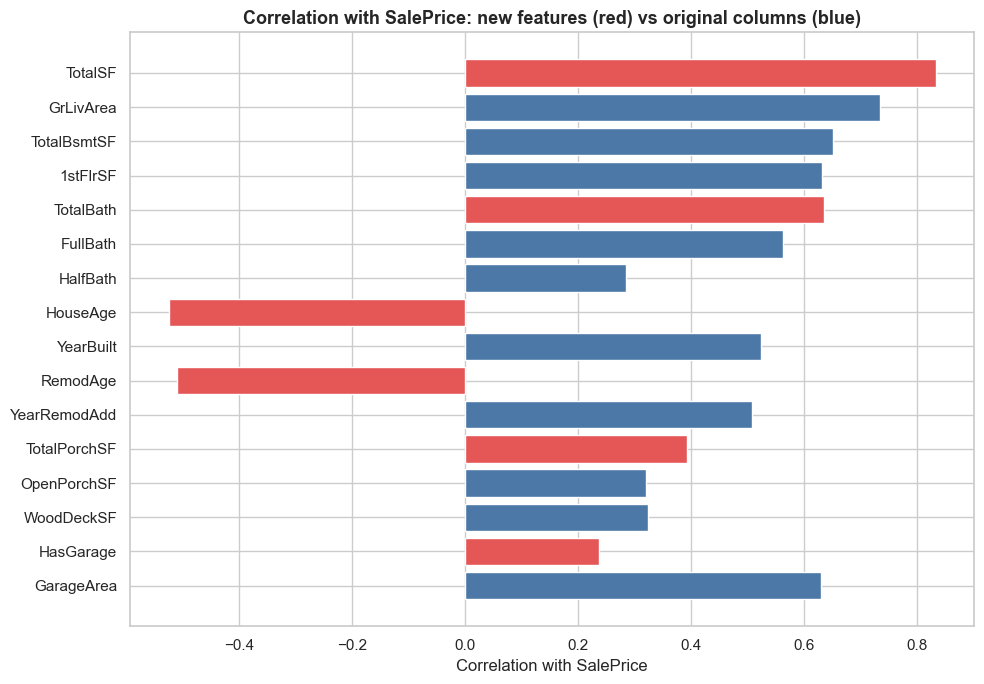

,correlation with SalePrice
TotalSF,0.833
GrLivArea,0.735
TotalBsmtSF,0.651
1stFlrSF,0.632
TotalBath,0.636
FullBath,0.562
HalfBath,0.285
HouseAge,-0.524
YearBuilt,0.524
RemodAge,-0.510


In [148]:
compare_cols = ["TotalSF", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
                "TotalBath", "FullBath", "HalfBath",
                "HouseAge", "YearBuilt", "RemodAge", "YearRemodAdd",
                "TotalPorchSF", "OpenPorchSF", "WoodDeckSF",
                "HasGarage", "GarageArea"]

corr_compare = train[compare_cols].corrwith(train["SalePrice"])

colors = ["#E45756" if c in new_features else "#4C78A8" for c in compare_cols]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(compare_cols[::-1], corr_compare[compare_cols].values[::-1], color=colors[::-1])
ax.set_title("Correlation with SalePrice: new features (red) vs original columns (blue)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Correlation with SalePrice")
plt.tight_layout()
plt.savefig(FIG / "new_features_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr_compare.round(3).to_frame("correlation with SalePrice")

**What it shows.** Correlation with the price for each new feature (red) next to the columns it was built from (blue).
- **`TotalSF`** (0.833) is stronger than each of its parts: `TotalBsmtSF` (0.651), `1stFlrSF` (0.632) and even `GrLivArea` (0.735). It is now the best size feature.
- **`TotalBath`** (0.636) is stronger than `FullBath` (0.562) and `HalfBath` (0.285).
- **`TotalPorchSF`** (0.393) is stronger than each single porch column (`OpenPorchSF` 0.321, `WoodDeckSF` 0.325).
- **`HouseAge`** (-0.524) and **`RemodAge`** (-0.510) are negative (older = cheaper). They are about as strong as `YearBuilt` (0.524) and `YearRemodAdd` (0.508), just flipped. They carry the same information in a form that is easier to read, so they do not beat the original columns in correlation.

**Why it matters.** Three of the new features are clearly better than the columns they were made from (`TotalSF`, `TotalBath`, `TotalPorchSF`). The age features are easier to explain. A proper test of the gain (with a model) happens in `02_Models.ipynb`.

---
# B7. Select and encode

**Goal:** make two tables that contain only useful numeric columns, with exactly the same columns in train and in test, and save them.

**Steps**
1. Remember the test `Id`s (needed for the Kaggle file), then drop `Id`.
2. Drop columns that are not useful.
3. Turn `MSSubClass` into text, because it is a code and not a quantity.
4. Join train and test, turn every text column into 0/1 columns with `pd.get_dummies`, then split them again. If we encoded them separately, a category that appears only in one table would give the two tables different columns, and the model could not predict test.
5. Keep `log1p(SalePrice)` as the target in train.
6. Check everything and save.

Joining the tables for `get_dummies` is safe: it only lists the categories, it does not learn any number from test.

In [149]:
# 1) the test Ids must be the same, in the same order, as the Kaggle sample submission
sample_submission = pd.read_csv(RAW / "sample_submission.csv")
assert (test["Id"].values == sample_submission["Id"].values).all()
print("Test Ids match sample_submission.csv:", len(test), "houses, same order")

# 2) columns to drop
cat_cols = train.select_dtypes("object").columns
near_constant = [c for c in cat_cols if train[c].value_counts(normalize=True).iloc[0] > 0.99]
print("Near-constant text columns (> 99% the same value):", near_constant)

drop_cols = ["Id", "GarageYrBlt"] + near_constant

Test Ids match sample_submission.csv: 1459 houses, same order
Near-constant text columns (> 99% the same value): ['Street', 'Utilities', 'Condition2', 'PoolQC']


**What it shows.** The test `Id`s are the same as in `sample_submission.csv`, in the same order. So in `02_Models.ipynb` we can use `sample_submission["Id"]` for the submission file and do not need to keep `Id` in the data.

**Columns we drop and why**
- **`Id`**: it is only a row number and tells nothing about the price.
- **`Street`, `Utilities`, `Condition2`, `PoolQC`**: more than 99% of the houses have the same value, so these columns cannot explain price differences. They only add noise.
- **`GarageYrBlt`**: we filled the houses without a garage with 0, which is a fake year very far from the real ones (1900 to 2010). It also repeats `YearBuilt` (the garage is usually built with the house). `HasGarage` keeps the useful part.

In [150]:
X_train = train.drop(columns=drop_cols + ["SalePrice"]).reset_index(drop=True)
X_test = test.drop(columns=drop_cols).reset_index(drop=True)
y_log = np.log1p(train["SalePrice"]).reset_index(drop=True)

# MSSubClass is a code (20, 60, 190, ...), not a quantity -> treat as text
for df in [X_train, X_test]:
    df["MSSubClass"] = df["MSSubClass"].astype(str)

# join -> one-hot encode -> split again
n_train = len(X_train)
all_data = pd.concat([X_train, X_test], axis=0, ignore_index=True)
all_data = pd.get_dummies(all_data, dtype=int)

train_processed = all_data.iloc[:n_train].copy()
test_processed = all_data.iloc[n_train:].copy().reset_index(drop=True)
train_processed["SalePrice_log"] = y_log

print("Columns before encoding:", X_train.shape[1])
print("Columns after encoding: ", test_processed.shape[1])
print("train_processed:", train_processed.shape, "| test_processed:", test_processed.shape)

Columns before encoding: 80
Columns after encoding:  305
train_processed: (1458, 306) | test_processed: (1459, 305)


**What it shows.** Before encoding each table has 80 columns. After `get_dummies`, each category becomes its own 0/1 column (for example `Neighborhood_NridgHt`), so we have 305 feature columns. Train also has the target column `SalePrice_log`.

**Why it matters.** Models need numbers. Because we encoded both tables together and split them afterwards, they have exactly the same feature columns.

**Note.** The column `MSSubClass_150` is 0 for every train house (only one test house has this building type), so for the model it changes nothing. We keep it so that train and test have exactly the same columns.

In [151]:
feature_cols = test_processed.columns

assert list(train_processed[feature_cols].columns) == list(test_processed.columns)   # same columns, same order
assert train_processed.isna().sum().sum() == 0 and test_processed.isna().sum().sum() == 0
assert len(train_processed) == 1458 and len(test_processed) == 1459
assert (train_processed.dtypes != "object").all() and (test_processed.dtypes != "object").all()
assert np.isfinite(train_processed.to_numpy()).all() and np.isfinite(test_processed.to_numpy()).all()

train_processed.to_csv(PROCESSED / "train_processed.csv", index=False)
test_processed.to_csv(PROCESSED / "test_processed.csv", index=False)
print("Saved:", PROCESSED / "train_processed.csv", "and", PROCESSED / "test_processed.csv")

Saved: ../data/processed/train_processed.csv and ../data/processed/test_processed.csv


**What it shows.** All checks passed and the two files were saved to `data/processed/`.

**What the checks mean:** same columns in the same order, no missing values, 1458 train rows (2 outliers removed) and 1459 test rows (none removed), only numbers, no infinite values.

**For the next notebook.** `train_processed.csv` has the target in the column `SalePrice_log` (already `log1p(SalePrice)`). To get dollars back, use `np.expm1`.

---
# Key findings

1. **The price is lopsided, so we model its log.** `SalePrice` has a skew of 1.88; after `log1p` it is 0.12. This also matches the Kaggle score.
2. **Missing values mostly mean "the house does not have it".** 19 train columns had gaps, mostly pool, alley, fence, garage and basement. We filled them with `"None"` or `0`, and used train medians and modes for the rest. Now both tables have 0 missing values.
3. **Quality is the biggest price driver.** `OverallQual` has a correlation of 0.79 with the price. Size (living area, garage, basement) is next.
4. **Location matters.** The median price of the most expensive neighborhood is about 3.6 times the cheapest one.
5. **Two outliers were removed from train.** Houses 524 and 1299 are huge but sold for a low price (unfinished-house sales). Removing them made the size-price link stronger (0.709 to 0.735).
6. **New features help.** `TotalSF` (0.833), `TotalBath` (0.636) and `TotalPorchSF` (0.393) correlate more with the price than the columns they were built from.
7. **Some columns repeat each other** (for example `GarageCars` and `GarageArea`), so Ridge or Lasso are a good choice for the models.

**Output:** `train_processed.csv` (1458 rows, 305 features + `SalePrice_log`) and `test_processed.csv` (1459 rows, 305 features), saved in `data/processed/`.